In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import logomaker
import glob

In [3]:
import os

if not os.path.isdir('apc_figures'):
    os.mkdir('apc_figures')

```
Required directory structure for this notebook to run

isoforms/  
    APCanalysis/  
        apc_figures.ipynb (this notebook)  
        figure_data/
            sg_rnaseq_pwm_20bp.csv
    data/  
        APCisos_*.tar.gz
        BLI_*.tar.gz 
        APCisos_*/  
        *.isodif.bins  
        *.isodif.ranked  
        bigo.csv  
```

```
Figure 1 Simulated APC Isoform Counts
Run bigo.py to get bigo.csv
```

In [4]:
iso_sim = pd.read_csv('../data/bigo.csv')
iso_sim = iso_sim[:len(iso_sim)-1]
# log1p is 1+input array, avoids issues due to 0s
iso_sim['iso_count_log1p'] = np.log1p(iso_sim['iso_count'])
iso_sim

,seq_len,iso_count,n_dons,n_accs,time,iso_count_log1p
0,300,0,1,4,0.000015,0.000000
1,300,0,1,6,0.000012,0.000000
2,300,0,3,1,0.000011,0.000000
3,300,0,4,1,0.000010,0.000000
4,300,0,3,2,0.000010,0.000000
...,...,...,...,...,...,...
1895,1200,3674284992,44,50,5579.225449,22.024624
1896,1200,3143083259,54,46,3402.269098,21.868470
1897,1200,10550340359,52,52,15370.186402,23.079424
1898,1200,10709534879,48,50,10133.434150,23.094400


In [5]:
xt_labs = [x for x in iso_sim['seq_len'].unique() if x % 100 == 0]

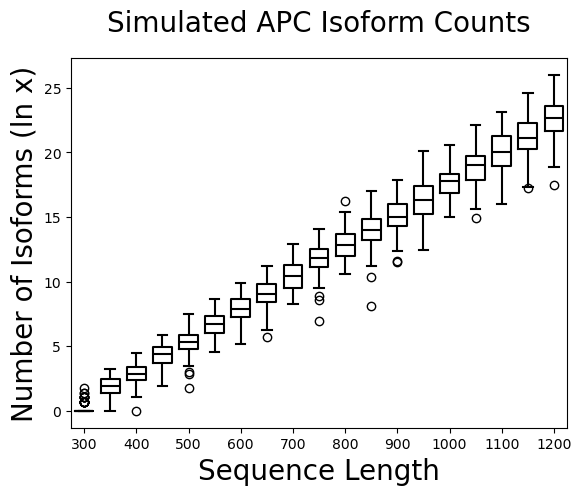

In [6]:
sim_bplot = sns.boxplot(data=iso_sim, x='seq_len', y='iso_count_log1p', fill=False, gap=.1, color='black')
sim_bplot.set_xticks(range(len(iso_sim['seq_len'].unique())))
sim_bplot.set_xticks([0, 2, 4, 6, 8, 10, 12, 14, 16, 18], xt_labs)
sim_bplot.set_xlabel("Sequence Length", fontsize='20')
sim_bplot.set_ylabel("Number of Isoforms (ln x)", fontsize='20')
sim_bplot.set_title("Simulated APC Isoform Counts", fontsize='20', y=1.05)

fig = sim_bplot.get_figure()
fig.savefig("apc_figures/apc_sim.png", format="png", bbox_inches="tight")

```
Sequence logos for figures 6 and 7
Run pwm2csv.py to get pwm csvs
```

In [7]:
pwm20 = pd.read_csv('figure_data/sg_rnaseq_pwm_20bp.csv', header=None)
pwm20.head(10)

,0,1,2,3,4
0,smallgenes_rnaseq_relative_donpwm,0.032819,0.014615,0.014838,0.026514
1,smallgenes_rnaseq_relative_donpwm,0.019318,0.009823,0.010735,0.013278
2,smallgenes_rnaseq_relative_donpwm,0.038890,0.024539,0.018565,0.014966
3,smallgenes_rnaseq_relative_donpwm,0.143828,0.038324,0.031651,0.060549
4,smallgenes_rnaseq_relative_donpwm,0.069109,0.033438,0.244270,0.063508
5,smallgenes_rnaseq_relative_donpwm,0.000000,0.000000,2.000000,0.000000
6,smallgenes_rnaseq_relative_donpwm,0.000000,0.000000,0.000000,2.000000
7,smallgenes_rnaseq_relative_donpwm,0.364980,0.008178,0.122333,0.095131
8,smallgenes_rnaseq_relative_donpwm,0.517074,0.041288,0.053633,0.111615
9,smallgenes_rnaseq_relative_donpwm,0.075285,0.026691,0.704060,0.103733


In [8]:
pwm20_don = (pwm20[pwm20[0] == 'smallgenes_rnaseq_relative_donpwm']
    .drop(columns=pwm20.columns[0])
    .rename(columns={1: 'A', 2: 'C', 3: 'G', 4: 'T'}))
pwm20_don.head(5)

,A,C,G,T
0,0.032819,0.014615,0.014838,0.026514
1,0.019318,0.009823,0.010735,0.013278
2,0.038890,0.024539,0.018565,0.014966
3,0.143828,0.038324,0.031651,0.060549
4,0.069109,0.033438,0.244270,0.063508


In [9]:
pwm20_acc = (pwm20[pwm20[0] == 'smallgenes_rnaseq_relative_accpwm']
    .drop(columns=pwm20.columns[0])
    .rename(columns={1: 'A', 2: 'C', 3: 'G', 4: 'T'}))
pwm20_acc.head(5)

,A,C,G,T
20,0.142444,0.043767,0.019292,0.100835
21,0.080952,0.033386,0.019210,0.086678
22,0.077257,0.032734,0.021609,0.100955
23,0.064045,0.027519,0.020824,0.077475
24,0.073747,0.031291,0.020163,0.086534


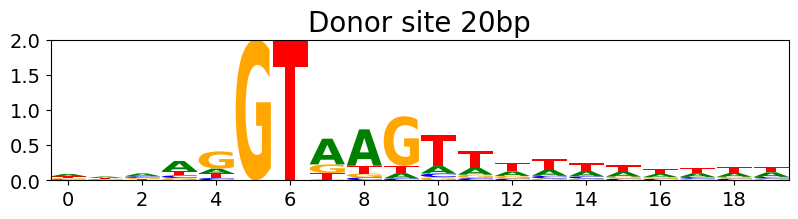

In [10]:
fig, ax = plt.subplots(1,1,figsize=[8,2])

don20_pwm = pwm20_don[0:].reset_index(drop=True)
don20_logo = logomaker.Logo(don20_pwm, ax=ax, shade_below=.5, fade_below=.5)

don20_logo.fig.tight_layout()
plt.title('Donor site 20bp', fontsize=20)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show
plt.savefig('don20pwm.svg', format='svg')

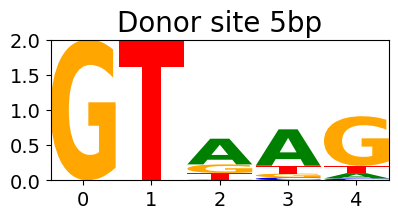

In [11]:
fig, ax = plt.subplots(1,1,figsize=[4,2])

don5_pwm = pwm20_don[5:10].reset_index(drop=True)
don5_logo = logomaker.Logo(don5_pwm, ax=ax, shade_below=.5, fade_below=.5)

don5_logo.fig.tight_layout()
plt.title('Donor site 5bp', fontsize=20)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.show
plt.savefig('don5pwm.svg', format='svg')

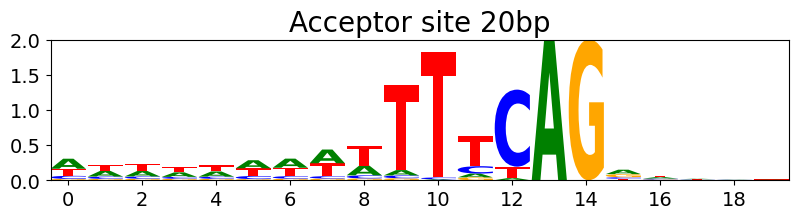

In [12]:
fig, ax = plt.subplots(1,1,figsize=[8,2])

acc20_pwm = pwm20_acc[0:].reset_index(drop=True)
acc20_logo = logomaker.Logo(acc20_pwm, ax=ax, shade_below=.5, fade_below=.5)

acc20_logo.fig.tight_layout()
plt.title('Acceptor site 20bp', fontsize=20)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show
plt.savefig('acc20pwm.svg', format='svg')

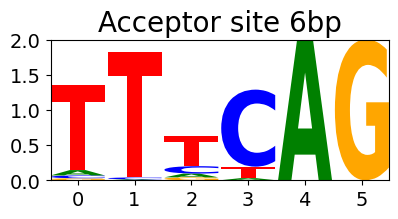

In [13]:
fig, ax = plt.subplots(1,1,figsize=[4,2])

acc5_pwm = pwm20_acc[9:15].reset_index(drop=True)
acc5_logo = logomaker.Logo(acc5_pwm, ax=ax, shade_below=.5, fade_below=.5)

acc5_logo.fig.tight_layout()
plt.title('Acceptor site 6bp', fontsize=20)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.show
plt.savefig('acc6pwm.svg', format='svg')

```
Figure 10 and 11
Summarizing distances
Run isodif to get rankings
```

In [14]:
base_ranked = pd.read_csv('figure_data/base.isodif.ranked')
base_dist = (
    base_ranked[['gene_id', 'dist']]
    .rename(columns={'dist': 'base'})
            )

optiso_ranked = pd.read_csv('figure_data/optiso.isodif.ranked')
optiso_dist = (
    optiso_ranked[['gene_id', 'dist']]
    .rename(columns={'dist': 'optiso'})
            )

nmd_ranked = pd.read_csv('figure_data/nmd.isodif.ranked')
nmd_dist = (
    nmd_ranked[['gene_id', 'dist']]
    .rename(columns={'dist': 'nmd'})
            )

optiso_nmd_ranked = pd.read_csv('figure_data/optiso_nmd.isodif.ranked')
optiso_nmd_dist = (
    optiso_nmd_ranked[['gene_id', 'dist']]
    .rename(columns={'dist': 'optiso_nmd'})
            )

In [15]:
from functools import reduce

dists = reduce(lambda left, right: left.merge(right, on='gene_id'), [base_dist, optiso_dist, nmd_dist, 
                                                                         optiso_nmd_dist])
dists

,gene_id,base,optiso,nmd,optiso_nmd
0,ce.1.23,0.998262,0.998398,0.998280,0.998403
1,ce.1.24,0.997658,0.997578,0.997663,0.997583
2,ce.1.27,0.997285,0.997267,0.997726,0.997677
3,ce.1.148,0.996723,0.996841,0.996723,0.996841
4,ce.1.71,0.996500,0.996715,0.996507,0.996781
...,...,...,...,...,...
916,ce.1.422,0.000000,0.150070,0.000000,0.240884
917,ce.1.513,0.000000,0.003316,0.000000,0.012200
918,ce.1.542,0.000000,0.000000,0.000000,0.000000
919,ce.1.500,0.000000,0.129710,0.000000,0.335794


In [16]:
less_than_75 = (
    dists[dists['optiso_nmd'] < 0.75]
    .sort_values('optiso_nmd', ascending=True)
    [['gene_id', 'optiso_nmd']]
)
less_than_75.to_csv('less_than_75.csv', index=False)

In [17]:
more_than_75 = (
    dists[dists['optiso_nmd'] > 0.75]
    .sort_values('optiso_nmd', ascending=True)
    [['gene_id', 'optiso_nmd']]
)
more_than_75.to_csv('more_than_75.csv', index=False)

In [18]:
dists[dists['optiso_nmd'] == 0]

,gene_id,base,optiso,nmd,optiso_nmd
695,ce.1.510,0.272618,0.0,0.308997,0.0
747,ce.1.538,0.221706,0.0,0.249543,0.0
893,ce.1.361,0.000072,0.0,0.000072,0.0
904,ce.1.514,0.000000,0.0,0.000000,0.0
910,ce.1.438,0.000000,0.0,0.000000,0.0
914,ce.1.496,0.000000,0.0,0.000000,0.0
918,ce.1.542,0.000000,0.0,0.000000,0.0
920,ce.1.507,0.000000,0.0,0.000000,0.0


```
Numbers for use when discussing figure 10 frequency polygon
```

In [19]:
(dists['optiso'] > 0.90).sum()

np.int64(259)

In [20]:
(dists['nmd'] > 0.90).sum()

np.int64(122)

In [21]:
(dists['base'] > 0.90).sum()

np.int64(80)

In [22]:
(dists['optiso_nmd'] > 0.90).sum()

np.int64(354)

```
How much do gene similarities change between the different types of APC?
```

In [23]:
dist_difs = dists.copy()
dist_difs.loc[:, 'base_to_opt_nmd'] = dists['optiso_nmd'] - dists['base']
dist_difs.loc[:, 'base_to_nmd'] = dists['nmd'] - dists['base']
dist_difs.loc[:, 'base_to_opt'] = dists['optiso'] - dists['base']

In [24]:
dist_difs.sort_values(by='base', ascending=True)
pd.set_option('display.max_rows', 20)

In [25]:
dd_sort1 = dist_difs.sort_values(by='base_to_opt_nmd', ascending=False)
dd_sort1

,gene_id,base,optiso,nmd,optiso_nmd,base_to_opt_nmd,base_to_nmd,base_to_opt
882,ce.1.118,0.000228,0.971298,0.123008,0.976538,0.976310,0.122780,0.971069
834,ce.1.415,0.007885,0.912908,0.326211,0.984128,0.976243,0.318326,0.905023
889,ce.1.430,0.000127,0.939579,0.017115,0.968454,0.968327,0.016989,0.939453
849,ce.1.402,0.003734,0.902259,0.581835,0.963154,0.959420,0.578101,0.898526
813,ce.1.186,0.030984,0.961585,0.041218,0.982910,0.951926,0.010234,0.930602
...,...,...,...,...,...,...,...,...
415,ce.1.200,0.495336,0.908617,0.478533,0.038846,-0.456490,-0.016803,0.413281
366,ce.3.48,0.524304,0.049994,0.407741,0.049994,-0.474310,-0.116563,-0.474310
370,ce.2.230,0.517971,0.029861,0.644031,0.029861,-0.488110,0.126060,-0.488110
51,ce.1.147,0.944911,0.960666,0.408611,0.339763,-0.605148,-0.536300,0.015755


In [26]:
base2optnmd = dd_sort1[['gene_id', 'optiso_nmd', 'base_to_opt_nmd']].copy()
base2optnmd

,gene_id,optiso_nmd,base_to_opt_nmd
882,ce.1.118,0.976538,0.976310
834,ce.1.415,0.984128,0.976243
889,ce.1.430,0.968454,0.968327
849,ce.1.402,0.963154,0.959420
813,ce.1.186,0.982910,0.951926
...,...,...,...
415,ce.1.200,0.038846,-0.456490
366,ce.3.48,0.049994,-0.474310
370,ce.2.230,0.029861,-0.488110
51,ce.1.147,0.339763,-0.605148


In [27]:
base2optnmd['rank'] = range(1, len(base2optnmd)+1)
base2optnmd

,gene_id,optiso_nmd,base_to_opt_nmd,rank
882,ce.1.118,0.976538,0.976310,1
834,ce.1.415,0.984128,0.976243,2
889,ce.1.430,0.968454,0.968327,3
849,ce.1.402,0.963154,0.959420,4
813,ce.1.186,0.982910,0.951926,5
...,...,...,...,...
415,ce.1.200,0.038846,-0.456490,917
366,ce.3.48,0.049994,-0.474310,918
370,ce.2.230,0.029861,-0.488110,919
51,ce.1.147,0.339763,-0.605148,920


In [28]:
base2nmd = dd_sort1[['gene_id', 'optiso_nmd', 'base_to_nmd']].copy()
base2nmd_rank_sim = base2nmd.sort_values(by='optiso_nmd', ascending=False)
base2nmd_rank_sim['rank'] = range(1, len(base2nmd_rank_sim)+1)
base2nmd_rank_sim

,gene_id,optiso_nmd,base_to_nmd,rank
5,ce.1.2,0.999982,0.000000,1
109,ce.1.150,0.999945,0.016081,2
40,ce.1.70,0.999935,0.040996,3
112,ce.1.302,0.999341,0.149637,4
6,ce.1.1,0.999198,0.000000,5
...,...,...,...,...
910,ce.1.438,0.000000,0.000000,917
914,ce.1.496,0.000000,0.000000,918
893,ce.1.361,0.000000,0.000000,919
904,ce.1.514,0.000000,0.000000,920


In [29]:
base2opt = dd_sort1[['gene_id', 'optiso_nmd', 'base_to_opt']].copy()
base2opt_rank_sim = base2opt.sort_values(by='optiso_nmd', ascending=False)
base2opt_rank_sim['rank'] = range(1, len(base2opt_rank_sim)+1)
base2opt_rank_sim

,gene_id,optiso_nmd,base_to_opt,rank
5,ce.1.2,0.999982,0.003572,1
109,ce.1.150,0.999945,0.158167,2
40,ce.1.70,0.999935,0.038544,3
112,ce.1.302,0.999341,0.028834,4
6,ce.1.1,0.999198,0.002833,5
...,...,...,...,...
910,ce.1.438,0.000000,0.000000,917
914,ce.1.496,0.000000,0.000000,918
893,ce.1.361,0.000000,-0.000072,919
904,ce.1.514,0.000000,0.000000,920


In [30]:
base2optnmd_rank_sim = base2optnmd.sort_values(by='optiso_nmd', ascending=False)
base2optnmd_rank_sim['rank'] = range(len(base2optnmd_rank_sim))
base2optnmd_rank_sim

,gene_id,optiso_nmd,base_to_opt_nmd,rank
5,ce.1.2,0.999982,0.003572,0
109,ce.1.150,0.999945,0.158307,1
40,ce.1.70,0.999935,0.041280,2
112,ce.1.302,0.999341,0.160418,3
6,ce.1.1,0.999198,0.002833,4
...,...,...,...,...
910,ce.1.438,0.000000,0.000000,916
914,ce.1.496,0.000000,0.000000,917
893,ce.1.361,0.000000,-0.000072,918
904,ce.1.514,0.000000,0.000000,919


In [31]:
base2optnmd[base2optnmd['base_to_opt_nmd'] < 0].drop(columns=['rank']).sort_values(by='optiso_nmd', ascending=False)

,gene_id,optiso_nmd,base_to_opt_nmd
1,ce.1.24,0.997583,-0.000075
10,ce.1.0,0.992823,-0.000577
81,ce.2.151,0.770691,-0.121816
92,ce.3.2,0.701587,-0.178268
96,ce.2.161,0.700685,-0.170787
...,...,...,...
628,ce.2.38,0.000051,-0.327500
845,ce.1.493,0.000010,-0.004627
893,ce.1.361,0.000000,-0.000072
695,ce.1.510,0.000000,-0.272618


In [32]:
(base2optnmd['base_to_opt_nmd'] < 0).sum()

np.int64(70)

In [33]:
(base2optnmd['base_to_opt_nmd'] >= 0).sum()

np.int64(851)

```
Figure 12 
Plots differences from base to each other type of APC
```

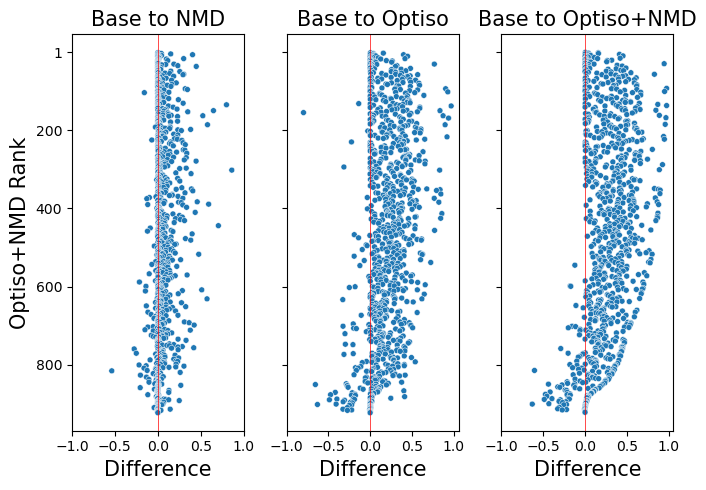

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(7, 5), sharey=True)

# base to nmd
sns.scatterplot(
    data=base2nmd_rank_sim,
    y='rank',
    x='base_to_nmd',
    size=50,
    legend=False,
    ax=axes[0]
)

axes[0].axvline(x=0, color='red', linewidth=0.5)
axes[0].set_title('Base to NMD', fontsize=15)
axes[0].set_ylabel('Optiso+NMD Rank', fontsize=15)
axes[0].set_xlabel('Difference', fontsize=15)

# base to optiso
sns.scatterplot(
    data=base2opt_rank_sim,
    y='rank',
    x='base_to_opt',
    size=50,
    legend=False,
    ax=axes[1]
)

axes[1].axvline(x=0, color='red', linewidth=0.5)
axes[1].set_title('Base to Optiso', fontsize=15)
axes[1].set_ylabel('')
axes[1].set_xlabel('Difference', fontsize=15)

# base to optiso+nmd
sns.scatterplot(
    data=base2optnmd_rank_sim,
    y='rank',
    x='base_to_opt_nmd',
    size=50,
    legend=False,
    ax=axes[2]
)

axes[2].axvline(x=0, color='red', linewidth=0.5)
axes[2].set_title('Base to Optiso+NMD', fontsize=15)
axes[2].set_ylabel('')
axes[2].set_xlabel('Difference', fontsize=15)

# apply to all plots
axes[0].invert_yaxis()
yticks = [0, 199, 399, 599, 799]
axes[0].set_yticks(yticks)
axes[0].set_yticklabels(['1', '200', '400', '600', '800'])

for ax in axes:
    ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])

plt.tight_layout()

plt.savefig('apc_figures/apc_type_differences.png', format='png')

In [35]:
dd_sort1.to_csv('dd_sort1.csv', index=False)

Figure 10

In [36]:
# create a frequency polygon

bins = [[round(x/10, 2), round(x/10 + 0.1, 2)] for x in range(0, 10, 1)]
# get mid point
bins = [(x[0], x[1], round((x[0] + x[1])/2, 3)) for x in bins]
bins

[(0.0, 0.1, 0.05),
 (0.1, 0.2, 0.15),
 (0.2, 0.3, 0.25),
 (0.3, 0.4, 0.35),
 (0.4, 0.5, 0.45),
 (0.5, 0.6, 0.55),
 (0.6, 0.7, 0.65),
 (0.7, 0.8, 0.75),
 (0.8, 0.9, 0.85),
 (0.9, 1.0, 0.95)]

In [37]:
# get frequency distributions

def get_dist_df(data, bins, col_name):
    
    bin_counts = {}
    for val in data:
        for bin in bins:
            if bin not in bin_counts:
                bin_counts[bin] = 0
            if val >= bin[0] and val < bin[1]:
                bin_counts[bin] += 1
            
    dfreq_data = {'mid': [], col_name: []}
    for item in bin_counts.items():
        dfreq_data['mid'].append(item[0][2])
        dfreq_data[col_name].append(item[1])

    dfreq_df = pd.DataFrame(dfreq_data)

    return dfreq_df

In [38]:
base_dfreq_df = get_dist_df(dist_difs['base'], bins, 'base_counts')
nmd_dfreq_df = get_dist_df(dist_difs['nmd'], bins, 'nmd_counts')
optiso_dfreq_df = get_dist_df(dist_difs['optiso'], bins, 'optiso_counts')
optiso_nmd_dfreq_df = get_dist_df(dist_difs['optiso_nmd'], bins, 'optiso_nmd_counts')

base_dfreq_df

,mid,base_counts
0,0.05,127
1,0.15,36
2,0.25,88
3,0.35,139
4,0.45,130
5,0.55,121
6,0.65,90
7,0.75,54
8,0.85,56
9,0.95,80


In [39]:
all_counts = pd.concat([
        base_dfreq_df, 
        nmd_dfreq_df['nmd_counts'], 
        optiso_dfreq_df['optiso_counts'],
        optiso_nmd_dfreq_df['optiso_nmd_counts']
    ], axis=1)
all_counts

,mid,base_counts,nmd_counts,optiso_counts,optiso_nmd_counts
0,0.05,127,103,78,53
1,0.15,36,17,28,18
2,0.25,88,70,36,22
3,0.35,139,117,30,36
4,0.45,130,140,71,72
5,0.55,121,107,56,45
6,0.65,90,113,110,76
7,0.75,54,69,99,79
8,0.85,56,63,154,166
9,0.95,80,122,259,354


In [40]:
all_counts_melt = pd.melt(all_counts, ['mid'])
all_counts_melt

,mid,variable,value
0,0.05,base_counts,127
1,0.15,base_counts,36
2,0.25,base_counts,88
3,0.35,base_counts,139
4,0.45,base_counts,130
...,...,...,...
35,0.55,optiso_nmd_counts,45
36,0.65,optiso_nmd_counts,76
37,0.75,optiso_nmd_counts,79
38,0.85,optiso_nmd_counts,166


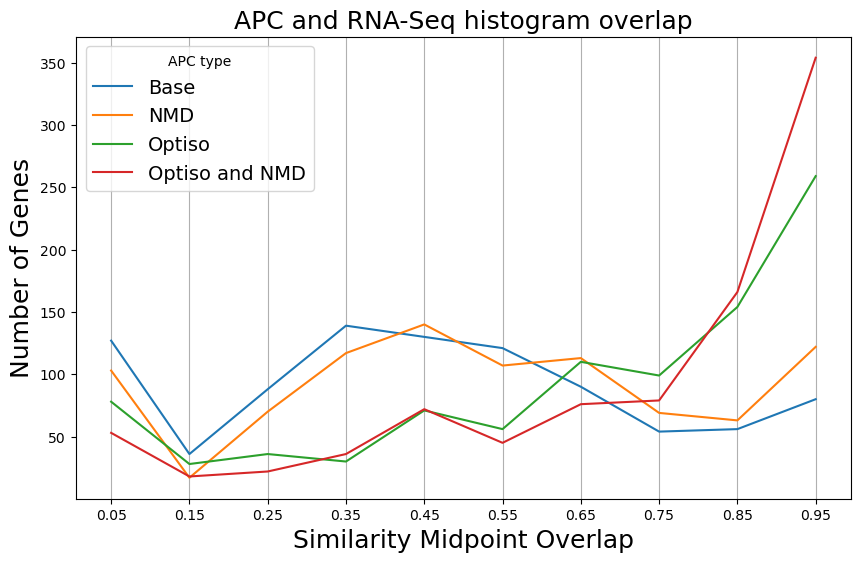

In [41]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x='mid', y='value', hue='variable',
        data=all_counts_melt)
ax.set_xticks(base_dfreq_df['mid'])
ax.xaxis.grid(True)
ax.set_title('APC and RNA-Seq histogram overlap', fontsize=18)
ax.set_xlabel('Similarity Midpoint Overlap', fontsize=18)
ax.set_ylabel('Number of Genes', fontsize=18)

# change only the legend labels and not the colors (color handles)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles,
         labels=['Base', 'NMD', 'Optiso', 'Optiso and NMD'],
         title='APC type',
         fontsize=14)

#plt.savefig('apc_figures/freq_poly.svg', format='svg')
plt.savefig('apc_figures/freq_poly.png', format='png')

In [42]:
from matplotlib.colors import to_hex

# get exact colors for each APC type
lab_colors = {}
for h, l in zip(handles, labels):
    hexc = to_hex(h.get_color())
    atype = '_'.join(l.split('_')[:-1])
    lab_colors[atype] = hexc

lab_colors

{'base': '#1f77b4',
 'nmd': '#ff7f0e',
 'optiso': '#2ca02c',
 'optiso_nmd': '#d62728'}

In [43]:
dist_melt = dists.melt(['gene_id'])
dist_melt

,gene_id,variable,value
0,ce.1.23,base,0.998262
1,ce.1.24,base,0.997658
2,ce.1.27,base,0.997285
3,ce.1.148,base,0.996723
4,ce.1.71,base,0.996500
...,...,...,...
3679,ce.1.422,optiso_nmd,0.240884
3680,ce.1.513,optiso_nmd,0.012200
3681,ce.1.542,optiso_nmd,0.000000
3682,ce.1.500,optiso_nmd,0.335794


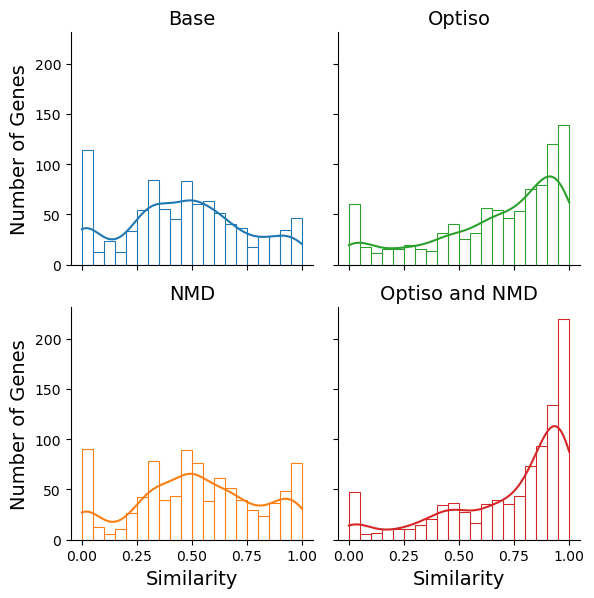

In [44]:
multi_h = sns.FacetGrid(dist_melt, col='variable', hue='variable', col_wrap=2, palette=lab_colors)
multi_h.map(sns.histplot, 'value', bins=20, kde=True, fill=False)
var_titles = ['Base', 'Optiso', 'NMD', 'Optiso and NMD']
for ax, vt in zip(multi_h.axes.flat, var_titles):
    ax.set_ylabel('Number of Genes', fontsize=14)
    ax.set_xlabel('Similarity', fontsize=14)
    ax.set_title(vt, fontsize=14)

In [45]:
# plot exon/intron length model for export into apc.svg
elen = pd.read_csv('../models/exon.len')
elen = elen.rename(columns={elen.columns[0]: 'Probability'})
elen.loc[:, 'Length'] = elen.index
elen

,Probability,Length
0,0.000000,0
1,0.000000,1
2,0.000000,2
3,0.000000,3
4,0.000000,4
...,...,...
995,0.000008,995
996,0.000008,996
997,0.000008,997
998,0.000008,998


In [46]:
ilen = pd.read_csv('../models/intron.len')
ilen = ilen.rename(columns={ilen.columns[0]: 'Probability'})
ilen.loc[:, 'Length'] = ilen.index
ilen

,Probability,Length
0,0.000000,0
1,0.000000,1
2,0.000000,2
3,0.000000,3
4,0.000000,4
...,...,...
995,0.000007,995
996,0.000006,996
997,0.000006,997
998,0.000006,998


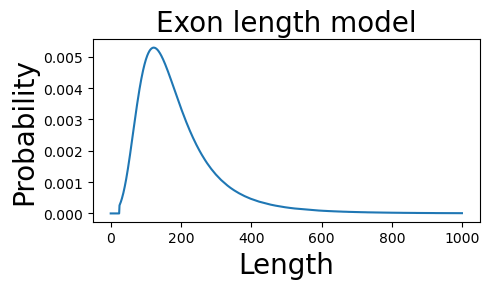

In [47]:
plt.figure(figsize=(5, 3))
ax = sns.lineplot(data=elen, x='Length', y='Probability')
ax.set_xlabel('Length', fontsize=20)
ax.set_ylabel('Probability', fontsize=20)
plt.title('Exon length model', fontsize=20)
plt.tight_layout()
plt.savefig('elen.svg', format='svg')

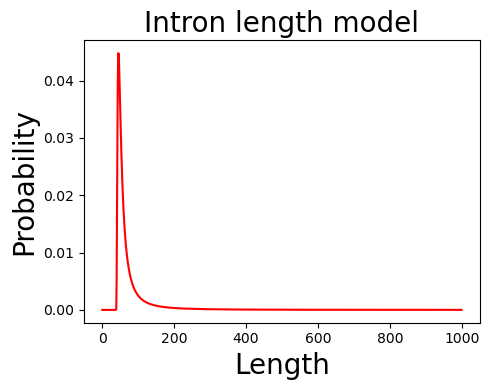

In [48]:
plt.figure(figsize=(5, 4))
ax = sns.lineplot(data=ilen, x='Length', y='Probability', color='red')
ax.set_xlabel('Length', fontsize=20)
ax.set_ylabel('Probability', fontsize=20)
plt.title('Intron length model', fontsize=20)
plt.tight_layout()
plt.savefig('ilen.svg', format='svg')

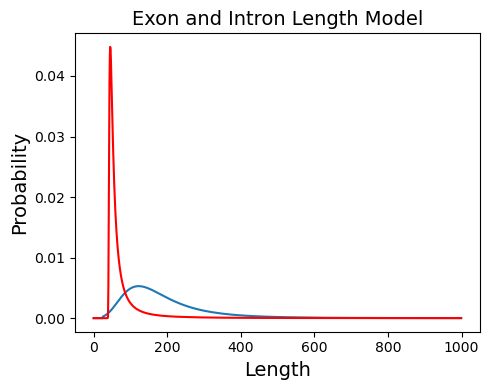

In [49]:
plt.figure(figsize=(5, 4))
ax = sns.lineplot(data=elen, x='Length', y='Probability')
sns.lineplot(data=ilen, x='Length', y='Probability', color='red')
plt.title('Exon and Intron Length Model', fontsize=14)
ax.set_xlabel('Length', fontsize=14)
ax.set_ylabel('Probability', fontsize=14)
plt.tight_layout()

In [50]:
dist_melt
dist_melt = dist_melt.rename(columns={'variable': 'apc_type', 'value': 'distance'})
dist_melt

,gene_id,apc_type,distance
0,ce.1.23,base,0.998262
1,ce.1.24,base,0.997658
2,ce.1.27,base,0.997285
3,ce.1.148,base,0.996723
4,ce.1.71,base,0.996500
...,...,...,...
3679,ce.1.422,optiso_nmd,0.240884
3680,ce.1.513,optiso_nmd,0.012200
3681,ce.1.542,optiso_nmd,0.000000
3682,ce.1.500,optiso_nmd,0.335794


In [51]:
# gc_stats.py is meant to be used only on smallgenes, not APC results 
gc_avg = pd.read_csv('gc_content/rna_gc_avg.csv')
dist_gc = dist_melt.merge(gc_avg, how='left', on='gene_id')
dist_gc

,gene_id,apc_type,distance,cds_gc_avg,int_gc_avg
0,ce.1.23,base,0.998262,50.24,22.06
1,ce.1.24,base,0.997658,42.48,46.15
2,ce.1.27,base,0.997285,49.52,27.66
3,ce.1.148,base,0.996723,58.97,34.69
4,ce.1.71,base,0.996500,55.88,31.82
...,...,...,...,...,...
3679,ce.1.422,optiso_nmd,0.240884,48.73,30.00
3680,ce.1.513,optiso_nmd,0.012200,46.70,59.83
3681,ce.1.542,optiso_nmd,0.000000,42.70,36.73
3682,ce.1.500,optiso_nmd,0.335794,41.47,34.87


In [52]:
dist_gc_optnmd = dist_gc[dist_gc['apc_type'] == 'optiso_nmd']
dist_gc_optnmd = dist_gc_optnmd.sort_values(by='distance')

In [53]:
dist_gc_optnmd.to_csv('dist_gc.csv', index=False)

In [54]:
dist_gc.loc[dist_gc['gene_id'] == 'ce.1.23']

,gene_id,apc_type,distance,cds_gc_avg,int_gc_avg
0,ce.1.23,base,0.998262,50.24,22.06
921,ce.1.23,optiso,0.998398,50.24,22.06
1842,ce.1.23,nmd,0.998280,50.24,22.06
2763,ce.1.23,optiso_nmd,0.998403,50.24,22.06


In [80]:
dist_bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
dist_gc_optnmd

,gene_id,apc_type,distance,cds_gc_avg,int_gc_avg,bin
3683,ce.1.507,optiso_nmd,0.000000,42.95,29.95,0.000000
3681,ce.1.542,optiso_nmd,0.000000,42.70,36.73,0.000000
3656,ce.1.361,optiso_nmd,0.000000,38.99,21.83,0.000000
3667,ce.1.514,optiso_nmd,0.000000,47.53,45.95,0.000000
3458,ce.1.510,optiso_nmd,0.000000,37.70,19.23,0.000000
...,...,...,...,...,...,...
2769,ce.1.1,optiso_nmd,0.999198,44.54,23.40,0.999198
2875,ce.1.302,optiso_nmd,0.999341,46.10,21.05,0.999341
2803,ce.1.70,optiso_nmd,0.999935,38.59,37.78,0.999935
2872,ce.1.150,optiso_nmd,0.999945,34.12,20.00,0.999945


In [82]:
def bins(val, bins):

    for i in range(len(bins)):
        if val > bins[i] and val < bins[i+1]:
            return bins[i]
        elif val == bins[i]:
            return bins[i]
        else:
            continue



r = bins(0.1, dist_bins)
print(r)
    

0.1


In [86]:
dist_gc_optnmd['bin'] = dist_gc_optnmd['distance'].apply(bins, args=(dist_bins,))

dist_gc_optnmd

,gene_id,apc_type,distance,cds_gc_avg,int_gc_avg,bin
3683,ce.1.507,optiso_nmd,0.000000,42.95,29.95,0.0
3681,ce.1.542,optiso_nmd,0.000000,42.70,36.73,0.0
3656,ce.1.361,optiso_nmd,0.000000,38.99,21.83,0.0
3667,ce.1.514,optiso_nmd,0.000000,47.53,45.95,0.0
3458,ce.1.510,optiso_nmd,0.000000,37.70,19.23,0.0
...,...,...,...,...,...,...
2769,ce.1.1,optiso_nmd,0.999198,44.54,23.40,0.9
2875,ce.1.302,optiso_nmd,0.999341,46.10,21.05,0.9
2803,ce.1.70,optiso_nmd,0.999935,38.59,37.78,0.9
2872,ce.1.150,optiso_nmd,0.999945,34.12,20.00,0.9


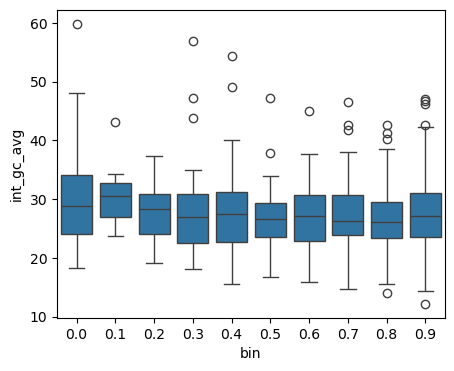

In [87]:
plt.figure(figsize=(5, 4))
ax = sns.boxplot(data=dist_gc_optnmd, x='bin', y='int_gc_avg')

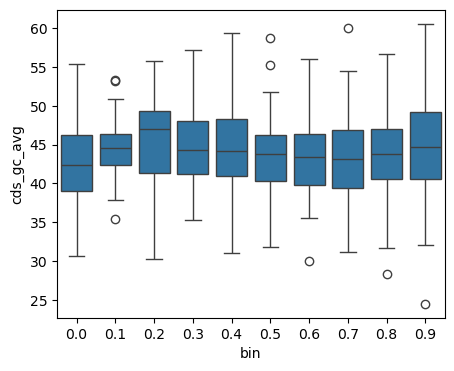

In [91]:
plt.figure(figsize=(5, 4))
ax = sns.boxplot(data=dist_gc_optnmd, x='bin', y='cds_gc_avg')

In [89]:
dist_gc_base = dist_gc[dist_gc['apc_type'] == 'base']
dist_gc_base = dist_gc_base.sort_values(by='distance')
dist_gc_base['bin'] = dist_gc_base['distance'].apply(bins, args=(dist_bins,))

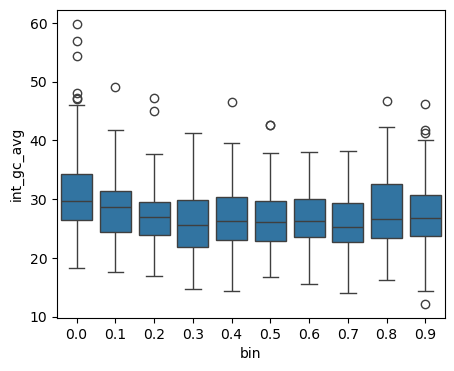

In [90]:
plt.figure(figsize=(5, 4))
ax = sns.boxplot(data=dist_gc_base, x='bin', y='int_gc_avg')

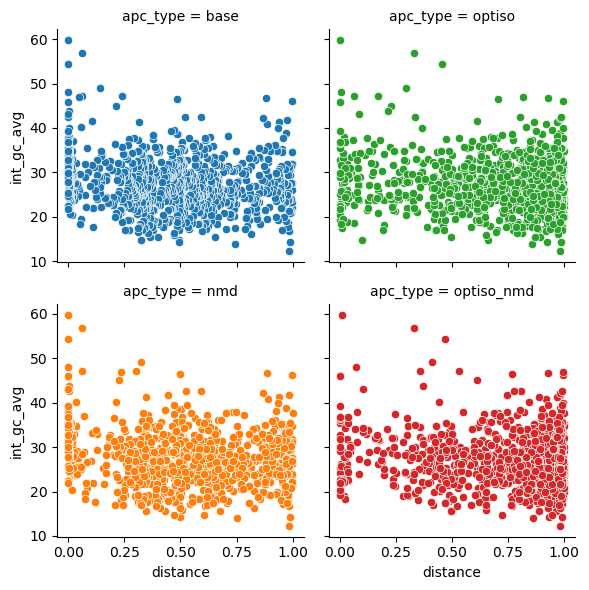

In [55]:
gc_avg_plt_int = sns.FacetGrid(dist_gc, col='apc_type', hue='apc_type', col_wrap=2, palette=lab_colors)
gc_avg_plt_int.map(sns.scatterplot, 'distance', 'int_gc_avg')

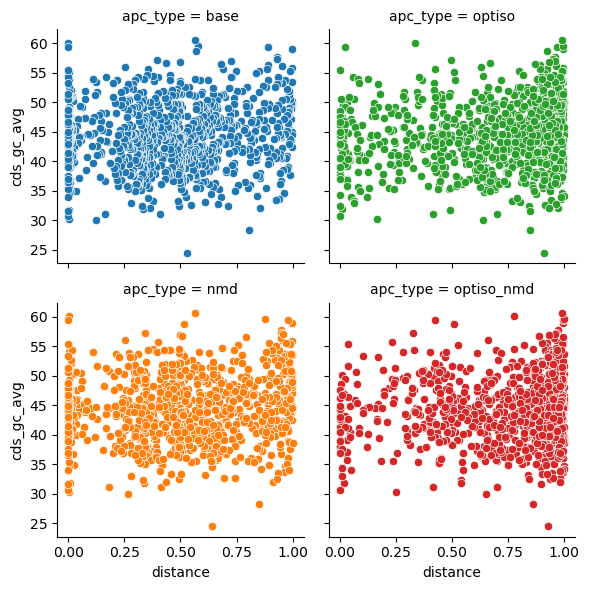

In [56]:
gc_avg_plt_cds = sns.FacetGrid(dist_gc, col='apc_type', hue='apc_type', col_wrap=2, palette=lab_colors)
gc_avg_plt_cds.map(sns.scatterplot, 'distance', 'cds_gc_avg')

In [ ]:
# from genome_stats.py
genomic_lengths = pd.read_csv('exin_genomic_lengths.csv')
genomic_lengths.head(10)

In [ ]:
ex_only = genomic_lengths[genomic_lengths['exin'] == 'exon']
in_only = genomic_lengths[genomic_lengths['exin'] == 'intron']

In [ ]:
elen_vals = ex_only[['length', 'counts']].values.tolist()
ilen_vals = in_only[['length', 'counts']].values.tolist()

In [ ]:
elens = []
exs_over = []
total_exs = 0
for pair in elen_vals:
    for i in range(pair[1]):
        total_exs += 1
        if pair[0] > 1000:
            exs_over.append(pair[0])
            continue
        elens.append(pair[0])

ilens = []
ins_over = []
total_ins = 0
for pair in ilen_vals:
    for i in range(pair[1]):
        total_ins += 1
        if pair[0] > 1000:
            ins_over.append(pair[0])
            continue
        ilens.append(pair[0])

In [ ]:
print(total_exs, len(exs_over), total_ins, len(ins_over))

In [ ]:
plt.figure(figsize=(5, 3))
ax = sns.histplot(data=elens)
plt.title('Protein Coding Exon Lengths', fontsize=20)
ax.set_xlabel('Length', fontsize=20)
ax.set_ylabel('Counts', fontsize=20)
plt.savefig('genomic_exlens_counts.svg', format='svg')

In [ ]:
plt.figure(figsize=(5, 3))
ax = sns.histplot(data=ilens)
plt.title('Protein Coding Intron Lengths', fontsize=20)
ax.set_xlabel('Length', fontsize=20)
ax.set_ylabel('Counts', fontsize=20)
plt.savefig('genomic_inlen_counts.svg', format='svg')

In [ ]:
import openturns as ot
import math

def create_length_model(lengths, lmin, lmax):
	
	# train Frechet
	sample = ot.Sample([[x] for x in lengths if x < lmax])
	f = ot.FrechetFactory().buildAsFrechet(sample)
	a = f.getAlpha()
	b = f.getBeta()
	g = f.getGamma()

	# create histogram from frechet
	pdf = []
	for x in range(lmax):
		if x < g: pdf.append(0)
		else:
			z = (x-g)/b
			pdf.append((a/b) * z**(-1-a) * math.exp(-z**-a))

	# create leading zeros and rescale
	for i in range(lmin): pdf[i] = 0
	total = sum(pdf)
	for i in range(len(pdf)): pdf[i] /= total

	return pdf

In [ ]:
gen_elen_mod = create_length_model(elens, 25, 1000)
gen_elen_df = pd.DataFrame(gen_elen_mod, columns=['probability'])
gen_elen_df.loc[:, 'length'] = gen_elen_df.index
gen_elen_df

In [ ]:
plt.figure(figsize=(5, 3))
ax = sns.lineplot(data=gen_elen_df, x='length', y='probability', label='genomic')
ax = sns.lineplot(data=elen, x='Length', y='Probability', label='smallgenes')
ax.set_xlabel('Length', fontsize=20)
ax.set_ylabel('Probability', fontsize=20)
plt.title('Exon length model', fontsize=20)
plt.tight_layout()
plt.savefig('gen_elen.svg', format='svg')

In [ ]:
gen_ilen_mod = create_length_model(ilens, 35, 1000)
gen_ilen_df = pd.DataFrame(gen_ilen_mod, columns=['probability'])
gen_ilen_df.loc[:, 'length'] = gen_ilen_df.index
gen_ilen_df

In [ ]:
plt.figure(figsize=(5, 3))
ax = sns.lineplot(data=gen_ilen_df, x='length', y='probability', label='genomic')
ax = sns.lineplot(data=ilen, x='Length', y='Probability', label='smallgenes')
ax.set_xlabel('Length', fontsize=20)
ax.set_ylabel('Probability', fontsize=20)
plt.title('Intron length model', fontsize=20)
plt.tight_layout()
plt.savefig('gen_ilen.svg', format='svg')

In [ ]:
# 0 weight testing
opt_no_emm = pd.read_csv('weight_testing/opt_no_emm.isodif.ranked')
no_emm_dist = (
    opt_no_emm[['gene_id', 'dist']]
    .rename(columns={'dist': 'no_emm'})
            )

opt_no_imm = pd.read_csv('weight_testing/opt_no_imm.isodif.ranked')
no_imm_dist = (
    opt_no_imm[['gene_id', 'dist']]
    .rename(columns={'dist': 'no_imm'})
            )

opt_no_exl = pd.read_csv('weight_testing/opt_no_exl.isodif.ranked')
no_exl_dist = (
    opt_no_exl[['gene_id', 'dist']]
    .rename(columns={'dist': 'no_exl'})
            )

opt_no_inl = pd.read_csv('weight_testing/opt_no_inl.isodif.ranked')
no_inl_dist = (
    opt_no_inl[['gene_id', 'dist']]
    .rename(columns={'dist': 'no_inl'})
            )

In [ ]:
w0_dists = reduce(lambda left, right: left.merge(right, on='gene_id'), [
    optiso_dist, no_emm_dist, no_imm_dist, no_exl_dist, no_inl_dist])

In [ ]:
w0_dists

In [ ]:
(w0_dists['optiso'] > 0.9).sum()

In [ ]:
(w0_dists['optiso'] > 0.6).sum()

In [ ]:
(w0_dists['no_emm'] > 0.9).sum()

In [ ]:
(w0_dists['no_emm'] > 0.6).sum()

In [ ]:
(w0_dists['no_imm'] > 0.9).sum()

In [ ]:
(w0_dists['no_imm'] > 0.6).sum()

In [ ]:
(w0_dists['no_imm'] < 0.2).sum()

In [ ]:
(w0_dists['optiso'] < 0.2).sum()

In [ ]:
no_imm_fd = get_dist_df(w0_dists['no_imm'], bins, 'no_imm_counts')
no_emm_fd = get_dist_df(w0_dists['no_emm'], bins, 'no_emm_counts')
no_exl_fd = get_dist_df(w0_dists['no_exl'], bins, 'no_exl_counts')
no_inl_fd = get_dist_df(w0_dists['no_inl'], bins, 'no_inl_counts')

In [ ]:
optiso_dfreq_df

In [ ]:
w0_counts = pd.concat([
    optiso_dfreq_df,
    no_imm_fd['no_imm_counts'],
    no_emm_fd['no_emm_counts'],
    no_exl_fd['no_exl_counts'],
    no_inl_fd['no_inl_counts']
    ], axis=1)

w0_counts

In [ ]:
w0_counts_melt = pd.melt(w0_counts, ['mid'])
w0_counts_melt

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x='mid', y='value', hue='variable', data=w0_counts_melt)
ax.set_xticks(optiso_dfreq_df['mid'])
ax.xaxis.grid(True)
ax.set_title('APC results with sub model removal', fontsize=18)
ax.set_xlabel('Similarity Midpoint Overlap', fontsize=18)
ax.set_ylabel('Number of genes', fontsize=18)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles,
        labels=['Optiso', 'No intron Markov model', 
                'No exon Markov model', 'No exon length model',
                'No intron length model'],
        title='APC type',
        fontsize=14
    )

plt.savefig('apc_figures/no_mm_no_len.png', format='png')

In [ ]:
# how are optiso weights distributed

In [ ]:
weights = pd.read_csv('../data/results_optisos.csv', dtype={'gid': str})
weights

In [ ]:
weights_sorted = weights.sort_values(by='fitness', ascending=True)
weights_sorted

In [ ]:
#test_df = weights_sorted[['gid', 'fitness', 'wacc', 'wdon', 'wexs']].copy()[:50]
#test_df

In [ ]:
#cols2sum = ['wacc', 'wdon', 'wexs']
#test_df[cols2sum] = test_df[cols2sum].cumsum(axis=1)
#test_df

In [ ]:
#f, ax = plt.subplots(figsize=(5, 10))
#sns.barplot(data=test_df, x='wexs', y='gid', color=colors[0], edgecolor='black')
#sns.barplot(data=test_df, x='wdon', y='gid', color=colors[1], edgecolor='black')
#sns.barplot(data=test_df, x='wacc', y='gid', color=colors[2], edgecolor='black')

In [ ]:
cols2sum = ['wacc', 'wdon', 'wexs', 'wins', 'wexl', 'winl', 'winf']
weights_summed = weights_sorted.copy()
weights_summed[cols2sum] = weights_summed[cols2sum].cumsum(axis=1)

In [ ]:
colors = sns.color_palette(palette='Accent')
colors = sns.color_palette("Greens_d", 7)

In [ ]:
subset1 = weights_summed[:50]

In [ ]:
subset2 = weights_summed[-50:]

In [ ]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 15))
# plot largest to smallest
# bars are on top of each other
sns.barplot(data=subset1, x='winf', y='gid', color=colors[0], ax=ax1)

sns.barplot(data=subset1, x='winl', y='gid', color=colors[1], ax=ax1)
sns.barplot(data=subset1, x='wexl', y='gid', color=colors[2], ax=ax1)

sns.barplot(data=subset1, x='wins', y='gid', color=colors[3], ax=ax1)
sns.barplot(data=subset1, x='wexs', y='gid', color=colors[4], ax=ax1)

sns.barplot(data=subset1, x='wdon', y='gid', color=colors[5], ax=ax1)
sns.barplot(data=subset1, x='wacc', y='gid', color=colors[6], ax=ax1)

ax1.set_title('Optiso weights top 50', fontsize=18)
ax1.set_xlabel(None)
ax1.set_xticks(ticks=[1, 2, 3, 4, 5, 6, 7])
ax1.set_ylabel('Gene ID', fontsize=18)

sns.barplot(data=subset2, x='winf', y='gid', color=colors[0], ax=ax2)

sns.barplot(data=subset2, x='winl', y='gid', color=colors[1], ax=ax2)
sns.barplot(data=subset2, x='wexl', y='gid', color=colors[2], ax=ax2)

sns.barplot(data=subset2, x='wins', y='gid', color=colors[3], ax=ax2)
sns.barplot(data=subset2, x='wexs', y='gid', color=colors[4], ax=ax2)

sns.barplot(data=subset2, x='wdon', y='gid', color=colors[5], ax=ax2)
sns.barplot(data=subset2, x='wacc', y='gid', color=colors[6], ax=ax2)

ax2.set_title('Optiso weights bottom 50', fontsize=18)
ax2.set_xlabel(None)
ax2.set_xticks(ticks=[1, 2, 3, 4, 5, 6, 7])
ax2.set_ylabel('Gene ID', fontsize=18)

labels = ["winf", "winl", "wexl", "wins", "wexs", "wdon", "wacc"]

handles = [
    plt.Rectangle((0, 0), 1, 1, color=c)
    for c in colors
]

ax1.legend(handles, labels, title='Weights', loc='lower right')
ax2.legend(handles, labels, title='Weights', loc='lower right')

plt.tight_layout()
plt.savefig('optiso_weights.png', dpi=1000)

In [ ]:
# ./geniso ../data/smallgenes/ce.1.538.fa ../models/worm.splicemodel --wacc 0.2647 --wdon 0.0980 --wexs 0.9882 --wins 0.0086 --wexl 0.0055 --winl 0.0039 --winf 0.9993 --limit 10000000

In [ ]:
dists

In [ ]:
dists[dists['gene_id'] == 'ce.3.64']

In [ ]:
utr_introns = pd.read_csv('utr_introns.csv')
#utr_introns

In [ ]:
utr_dists = utr_introns.merge(dists, on='gene_id', how='left')
#utr_dists

In [ ]:
utr_dists['dist'] = utr_dists.apply(lambda row: row[row['apc_type']], axis=1)
utr_dists = utr_dists.drop(columns=['base', 'optiso', 'nmd', 'optiso_nmd'])

In [ ]:
utr_dists

In [ ]:
base_top_25 = utr_dists[(utr_dists['apc_type'] == 'base') & 
            (utr_dists['dist'] >= 0.75)]
len(base_top_25[base_top_25['top_int_utr'] == True])

In [ ]:
len(base_top_25[base_top_25['top_int_utr'] == False])

In [ ]:
base_bot_75 = utr_dists[(utr_dists['apc_type'] == 'base') & 
            (utr_dists['dist'] < 0.75)]
len(base_bot_75[base_bot_75['top_int_utr'] == True])

In [ ]:
len(base_bot_75[base_bot_75['top_int_utr'] == False])

In [ ]:
optnmd_top_25 = utr_dists[(utr_dists['apc_type'] == 'optiso_nmd') & 
            (utr_dists['dist'] >= 0.75)]
len(optnmd_top_25[optnmd_top_25['top_int_utr'] == True])

In [ ]:
len(optnmd_top_25[optnmd_top_25['top_int_utr'] == False])

In [ ]:
optnmd_bot_75 = utr_dists[(utr_dists['apc_type'] == 'optiso_nmd') & 
            (utr_dists['dist'] < 0.75)]
len(optnmd_bot_75[optnmd_bot_75['top_int_utr'] == True])

In [ ]:
len(optnmd_bot_75[optnmd_bot_75['top_int_utr'] == False])

In [ ]:
# average similarity based on number of introns
#dists['n_introns'] = range(len(dists))
gid_list = dists['gene_id'].tolist()
n_ints = []
for gid in gid_list:
    n_ints.append(gid.split('.')[1])

dists['n_introns'] = n_ints

dists

In [ ]:
one_int = dists[dists['n_introns'] == '1']
two_int = dists[dists['n_introns'] == '2']
three_int = dists[dists['n_introns'] == '3']
four_int = dists[dists['n_introns'] == '4']

In [ ]:
print(len(one_int), len(two_int), len(three_int), len(four_int))

In [ ]:
one_int

In [ ]:
mean_sims = pd.concat(
    [one_int[['base', 'optiso', 'nmd', 'optiso_nmd']].mean(),
    two_int[['base', 'optiso', 'nmd', 'optiso_nmd']].mean(),
    three_int[['base', 'optiso', 'nmd', 'optiso_nmd']].mean(),
    four_int[['base', 'optiso', 'nmd', 'optiso_nmd']].mean()],
    axis=1,
    keys=['one_int', 'two_int', 'three_int', 'four_int'] 
).T

mean_sims

```
Biologically Likely Isoforms (BLI) 
```

In [92]:
# run isodif to get ranks

bli_base_ranked = pd.read_csv('figure_data/bli_base.isodif.ranked')
bli_base_dist = (
    bli_base_ranked[['gene_id', 'dist']]
    .rename(columns={'dist':'bli_base'})
)

bli_nmd_ranked = pd.read_csv('figure_data/bli_nmd.isodif.ranked')
bli_nmd_dist = (
    bli_nmd_ranked[['gene_id', 'dist']]
    .rename(columns={'dist':'bli_nmd'})
)

bli_optiso_ranked = pd.read_csv('figure_data/bli_optiso.isodif.ranked')
bli_optiso_dist = (
    bli_optiso_ranked[['gene_id', 'dist']]
    .rename(columns={'dist':'bli_optiso'})
)

bli_optnmd_ranked = pd.read_csv('figure_data/bli_optnmd.isodif.ranked')
bli_optnmd_dist = (
    bli_optnmd_ranked[['gene_id', 'dist']]
    .rename(columns={'dist':'bli_optnmd'})
)

In [93]:
bli_dists = reduce(lambda left, right: left.merge(right, on='gene_id'), 
                   [bli_base_dist, bli_nmd_dist, bli_optiso_dist, bli_optnmd_dist])
bli_dists

,gene_id,bli_base,bli_nmd,bli_optiso,bli_optnmd
0,ce.1.210,1.000000,1.000000,1.000000,1.000000
1,ce.1.220,1.000000,1.000000,1.000000,1.000000
2,ce.1.520,1.000000,1.000000,1.000000,1.000000
3,ce.1.22,1.000000,1.000000,1.000000,1.000000
4,ce.1.174,1.000000,1.000000,1.000000,1.000000
...,...,...,...,...,...
916,ce.1.513,0.000927,0.007535,0.978495,0.983687
917,ce.1.350,0.000853,0.038961,0.988241,0.989880
918,ce.1.517,0.000269,0.184654,0.674480,0.999601
919,ce.1.251,0.000142,0.016515,0.990338,0.991424


In [94]:
# create a frequency polygon

bins = [[round(x/10, 2), round(x/10 + 0.1, 2)] for x in range(0, 10, 1)]

# get mid point
bins = [(x[0], x[1], round((x[0] + x[1])/2, 3)) for x in bins]

bins

[(0.0, 0.1, 0.05),
 (0.1, 0.2, 0.15),
 (0.2, 0.3, 0.25),
 (0.3, 0.4, 0.35),
 (0.4, 0.5, 0.45),
 (0.5, 0.6, 0.55),
 (0.6, 0.7, 0.65),
 (0.7, 0.8, 0.75),
 (0.8, 0.9, 0.85),
 (0.9, 1.0, 0.95)]

In [95]:
# get frequency distributions
# see line 44
# def get_dist_df
bli_dists['bli_base']

0      1.000000
1      1.000000
2      1.000000
3      1.000000
4      1.000000
         ...   
916    0.000927
917    0.000853
918    0.000269
919    0.000142
920    0.000017
Name: bli_base, Length: 921, dtype: float64

In [96]:
bli_base_dfreqs = get_dist_df(bli_dists['bli_base'], bins, 'bli_base_counts')
bli_nmd_dfreqs = get_dist_df(bli_dists['bli_nmd'], bins, 'bli_nmd_counts')
bli_optiso_dfreqs = get_dist_df(bli_dists['bli_optiso'], bins, 'bli_optiso_counts')
bli_optnmd_dfreqs = get_dist_df(bli_dists['bli_optnmd'], bins, 'bli_optnmd_counts')

bli_base_dfreqs

,mid,bli_base_counts
0,0.05,33
1,0.15,11
2,0.25,8
3,0.35,18
4,0.45,35
5,0.55,66
6,0.65,66
7,0.75,49
8,0.85,92
9,0.95,435


In [97]:
bli_all_counts = pd.concat([
    bli_base_dfreqs,
    bli_nmd_dfreqs['bli_nmd_counts'],
    bli_optiso_dfreqs['bli_optiso_counts'],
    bli_optnmd_dfreqs['bli_optnmd_counts']
], axis=1)

bli_all_counts

,mid,bli_base_counts,bli_nmd_counts,bli_optiso_counts,bli_optnmd_counts
0,0.05,33,23,0,4
1,0.15,11,6,0,1
2,0.25,8,8,2,2
3,0.35,18,11,4,5
4,0.45,35,24,7,13
5,0.55,66,63,12,13
6,0.65,66,50,21,15
7,0.75,49,47,29,16
8,0.85,92,87,88,95
9,0.95,435,494,650,649


In [98]:
bli_all_counts_melt = pd.melt(bli_all_counts, ['mid'])
bli_all_counts_melt

,mid,variable,value
0,0.05,bli_base_counts,33
1,0.15,bli_base_counts,11
2,0.25,bli_base_counts,8
3,0.35,bli_base_counts,18
4,0.45,bli_base_counts,35
...,...,...,...
35,0.55,bli_optnmd_counts,13
36,0.65,bli_optnmd_counts,15
37,0.75,bli_optnmd_counts,16
38,0.85,bli_optnmd_counts,95


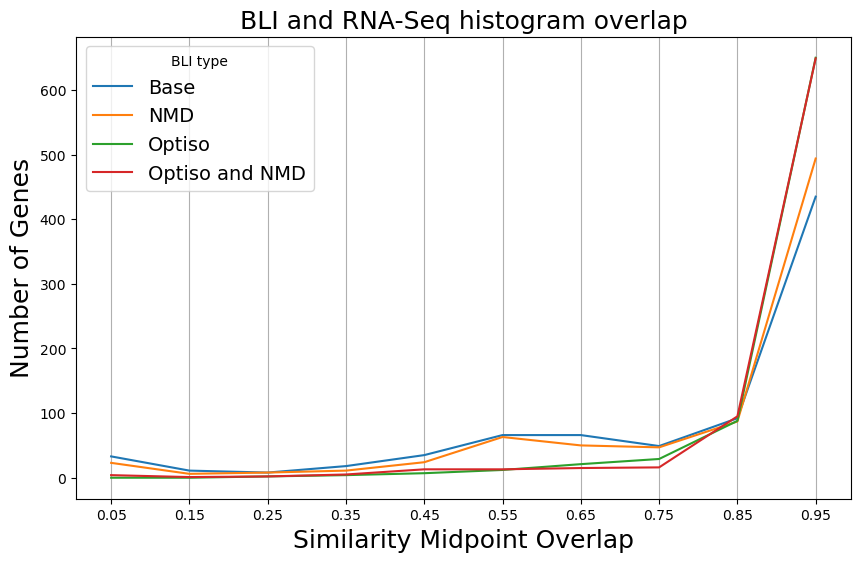

In [99]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x='mid', y='value', hue='variable',
            data=bli_all_counts_melt)
ax.set_xticks(bli_base_dfreqs['mid'])
ax.xaxis.grid(True)
ax.set_title('BLI and RNA-Seq histogram overlap', fontsize=18)
ax.set_xlabel('Similarity Midpoint Overlap', fontsize=18)
ax.set_ylabel('Number of Genes', fontsize=18)

# change only the legend labels and not the colors (color handles)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles,
    labels=['Base', 'NMD', 'Optiso', 'Optiso and NMD'],
    title='BLI type',
    fontsize=14
)